# EuroSAT lab 2 · LIME with superpixels: from perturbations to a local surrogate model

**Author:** Xiangqi Kong

**Deck:** Post-hoc Model-Agnostic (*Superpixels*, *LIME*) · **Follows:** the lecture on occlusion and LIME · **Runtime:** about 5–10 minutes on a T4 with the lab pack · **GPU:** helps

Occlusion removes **one** region at a time, so it misses regions that only matter **together**. LIME (Ribeiro et al., 2016) removes **random
combinations** of regions and fits a simple, interpretable model that mimics the black box *near this one image*:

$$\xi(x) = \arg\min_{g \in G} \; \mathcal{L}(f, g, \pi_x) + \Omega(g)$$

* **Interpretable features $z' \in \{0,1\}^d$:** is superpixel $j$ kept (1) or removed (0)? Removed = set to the training mean in all bands.
* **Proximity $\pi_x$:** samples that remove little are close to $x$ and get more weight.
* **Surrogate $g$:** a weighted ridge regression; its coefficients are the explanation, its weighted $R^2$ is the **fidelity**.

**Multispectral twist.** The interpretable features do not have to be pixels. Section 7 uses the **14 channels** as LIME's features, a local
counterpart of PCI.

**What you should see.** LIME highlights the superpixels that make up the class (the river, the road), but the result depends on the
segmentation, the number of samples, and the kernel width, and changes a little with every random seed.

> **Walkthrough version.** Nothing to fill in: the code is complete and the results are already shown, so you can read it without running it.
> **Every line of code has a plain comment above it** that says what it does and why, and after each result a **What to notice** note says what to look at.
> Read it before the lab, or open it next to the easy version when you are stuck.

> **In the lab session: about 25 minutes.** Do the sections marked 🟢 core in order; they are what we discuss at the end.
> Sections marked ⚪ if time can be skipped: no 🟢 core section needs them, so come back to them at home.
>
> 🟢 core: 1 superpixels, 2 LIME by hand (TODO 1, 2), 4 segmentation, 5 stability (TODO 3).  
> ⚪ if time: 3 two classes, 6 kernel width, 7 spectral LIME, 8 lime package.

## 0. Setup

> **What this cell does.** It installs the few Python packages that Colab does not have. Just run it; it takes about 10 seconds.

In [1]:
!pip -q install scikit-image lime

> **What this cell does.** It loads the libraries (NumPy, PyTorch, Matplotlib), fixes the random seed so everyone gets the same numbers, and checks whether a GPU is available. Just run it.

In [2]:
# Standard Python tools: files, random numbers, timing, downloading.
import os, random, time, urllib.request
from pathlib import Path
from collections import defaultdict

# The scientific libraries: arrays, tables, plots.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch: the model is a PyTorch network.
import torch
import torch.nn as nn
import torch.nn.functional as F

# spearmanr compares two rankings (1 = same order); tqdm draws progress bars.
from scipy.stats import spearmanr
from tqdm.auto import tqdm

# Fix every random number generator, so everybody gets the same numbers.
SEED = 42


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything()

# Use the GPU if Colab gave us one, otherwise the CPU (slower, but everything
# still runs).
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU = DEVICE.type == "cuda"
print("Device:", DEVICE, "| torch", torch.__version__)
if not GPU:
    print(
        "No GPU found: the notebook still runs, with smaller sample sizes (see the settings below)."
    )

# A plain look for all plots: no top and right border, a light grid.
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.axisbelow": True,
    }
)

Device: cpu | torch 2.15.0+cu132
No GPU found: the notebook still runs, with smaller sample sizes (see the settings below).


### Names
The classes, the bands and the colours used in the plots. Nothing to change here; just run it.

> **What this cell does.** It only sets names: the 10 land-cover classes, the 13 satellite bands and their spectral groups (with one colour per group for the plots). You do not need to change anything.

In [3]:
# Where the lab pack is downloaded from (the second address is a spare copy).
LAB_PACK_URLS = [
    "https://github.com/kxqdesign/XAILabData/raw/main/lab-data/eurosat_lab_pack_v1.npz",
    "https://github.com/kxqdesign/XAILabData/raw/main/lab-data/eurosat_lab_pack_v1.npz",
]
# How many images go through the model at once.
EVAL_BATCH = 512

# The 10 land-cover classes, in the order of the model's 10 outputs.
CLASSES = [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake",
]
# The 13 Sentinel-2 bands, in the order of the image channels.
BANDS = [
    "B01",
    "B02",
    "B03",
    "B04",
    "B05",
    "B06",
    "B07",
    "B08",
    "B09",
    "B10",
    "B11",
    "B12",
    "B8A",
]
# For every band: what it measures, its resolution in metres, and its spectral
# group.
BAND_INFO = {
    "B01": ("Coastal aerosol", 60, "Atmospheric"),
    "B02": ("Blue", 10, "Visible"),
    "B03": ("Green", 10, "Visible"),
    "B04": ("Red", 10, "Visible"),
    "B05": ("Red edge 1", 20, "Red edge"),
    "B06": ("Red edge 2", 20, "Red edge"),
    "B07": ("Red edge 3", 20, "Red edge"),
    "B08": ("NIR", 10, "NIR"),
    "B09": ("Water vapour", 60, "Atmospheric"),
    "B10": ("SWIR cirrus", 60, "Atmospheric"),
    "B11": ("SWIR 1", 20, "SWIR"),
    "B12": ("SWIR 2", 20, "SWIR"),
    "B8A": ("Narrow NIR", 20, "NIR"),
}
# One colour per spectral group, for the bar charts.
GROUP_COLORS = {
    "Visible": "#2a78d6",
    "Red edge": "#eb6834",
    "NIR": "#1baf7a",
    "SWIR": "#eda100",
    "Atmospheric": "#e87ba4",
    "Control": "#8a8985",
}
# The model sees 14 channels: the 13 bands plus NOISE, a channel of pure random
# noise.
# NOISE is a control: a good explanation method must give it an importance of
# about 0.
CHANNEL_NAMES = BANDS + ["NOISE"]
N_CH = len(CHANNEL_NAMES)
# The group of every channel, and the channel numbers of every group.
GROUP_OF = {**{b: BAND_INFO[b][2] for b in BANDS}, "NOISE": "Control"}
GROUPS = {
    g: [i for i, c in enumerate(CHANNEL_NAMES) if GROUP_OF[c] == g]
    for g in GROUP_COLORS
}

## 0. The model and the images: load the lab pack

**This is setup. Run the next cell and move on; you do not need to read it to follow the lab.**

It downloads a small *lab pack* (about 40 MB, a few seconds) that holds a CNN already trained on the EuroSAT satellite images and 500 of
its test images (50 per class). Nothing is trained in class. Every image has 14 channels: the 13 Sentinel-2 bands plus one channel of pure
noise that the model should ignore.

> **What this cell does.** **Just run it.** It defines the model (a small CNN), downloads the lab pack, loads the trained weights, and loads the 500 test images into `X`.

In [4]:
# ---- the model: a small CNN ----
class SmallCNN(nn.Module):
    def __init__(self, in_ch, n_classes=10, w=48):
        super().__init__()

        # One block = two times (3 x 3 convolution, batch norm, ReLU).
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1, bias=False),
                nn.BatchNorm2d(o),
                nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1, bias=False),
                nn.BatchNorm2d(o),
                nn.ReLU(inplace=True),
            )

        # Four blocks; after each of the first three the image is halved (64 ->
        # 32 -> 16 -> 8 pixels).
        self.features = nn.Sequential(
            block(in_ch, w),
            nn.MaxPool2d(2),
            block(w, 2 * w),
            nn.MaxPool2d(2),
            block(2 * w, 4 * w),
            nn.MaxPool2d(2),
            block(4 * w, 4 * w),
        )
        # Average every feature map to one number, then one linear layer gives
        # the 10 class scores.
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(4 * w, n_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))


# ---- download the lab pack (skipped if the file is already here, e.g. uploaded
# by hand)
PACK_FILE = Path("eurosat_lab_pack_v1.npz")
for url in LAB_PACK_URLS:
    if PACK_FILE.exists():
        break
    try:
        print(f"downloading the lab pack from {url} ...")
        urllib.request.urlretrieve(url, PACK_FILE)
    except Exception as e:
        print(f"  failed: {type(e).__name__}: {e}")
        PACK_FILE.unlink(missing_ok=True)
if not PACK_FILE.exists():
    raise RuntimeError(
        "Could not download the lab pack. Drag eurosat_lab_pack_v1.npz into the Colab Files panel and run this cell again."
    )
pack = np.load(PACK_FILE)

# ---- the trained model: put the saved weights into the network ----
model = SmallCNN(N_CH).to(DEVICE)
model.load_state_dict(
    {
        k[3:]: torch.from_numpy(pack[k])
        for k in pack.files
        if k.startswith("w::")
    }
)
# evaluation mode: no dropout, fixed batch-norm statistics
model.eval()

# ---- the test images ----
# Standardise every band with the mean and standard deviation of the training
# data.
# After this step the value 0 means "the average value of this band", which is
# how we will "remove" things later.
band_mean, band_std = pack["band_mean"], pack["band_std"]
x = (
    pack["X_test_raw"].astype(np.float32)
    - band_mean[None, :, None, None].astype(np.float32)
) / band_std[None, :, None, None].astype(np.float32)
# the true class of every test image
y_test = pack["y_test"].astype(np.int64)

# Add the noise channel: one fixed noise image per test image, so the model
# always gives the same answer for the same image.
NOISE = torch.randn(
    len(x), 1, 64, 64, generator=torch.Generator().manual_seed(SEED)
).half()
# X has shape (500, 14, 64, 64)
X = torch.cat([torch.from_numpy(x).half(), NOISE], 1)
del x, pack
print("test images:", tuple(X.shape))

test images: (500, 14, 64, 64)


> **What to notice.** The last line should read `test images: (500, 14, 64, 64)`: 500 images, 14 channels, 64 × 64 pixels.

### Prediction helpers and example images
`coalition_proba` is the one perturbation used by every method in these labs: *remove* a set of pixels or channels by setting them to the training mean, and read the probability of the class we explain.

> **What this cell does.** It defines four helpers used in the rest of the lab, then picks one example image per class.
> 
> - `predict_proba(x)`: the model's 10 class probabilities for an image.
> - `rgb(x)`: a true-colour picture of an image, for display only.
> - `show_map(...)`: draws an explanation on top of the picture (red = supports the class, blue = against it).
> - `coalition_proba(x, Z, target)`: **the key helper.** Each row of `Z` is a list of 1s and 0s: 1 = keep this part of the image, 0 = remove it (replace it by the average value). It returns the probability of the class `target` for every row. LIME and SHAP both work by calling this many times.

Test accuracy: 0.9580   (the PCI notebook reports the same model's baseline)


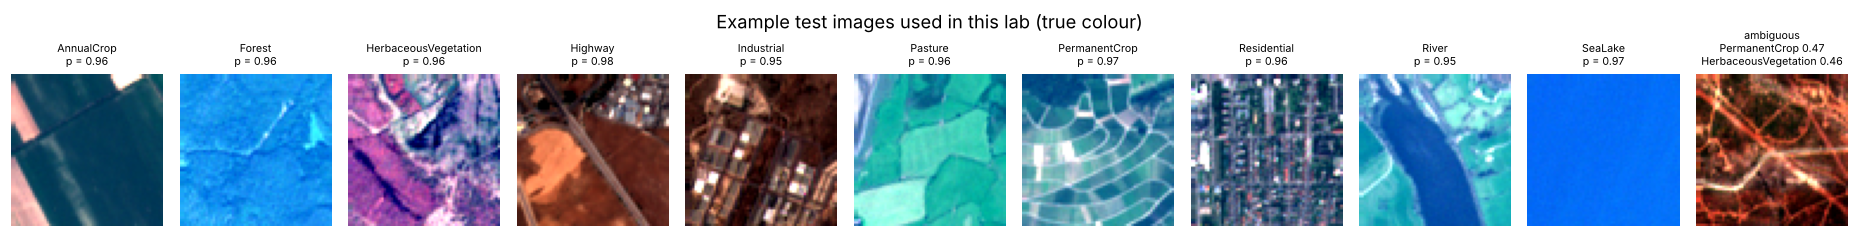

In [6]:
# ---------- predict_proba: image(s) in, class probabilities out ----------
# @torch.no_grad() tells PyTorch not to keep track of gradients here: we only
# want predictions, so this saves time and memory.
@torch.no_grad()
def predict_proba(x, batch=EVAL_BATCH):
    # A single image has 3 dimensions (14, H, W). The model wants a batch (N,
    # 14, H, W), so add a first dimension of size 1.
    if x.ndim == 3:
        x = x[None]
    # Go through the images in batches. For each batch: move it to the GPU/CPU,
    # run the model (this gives 10 scores per image),
    # turn the scores into probabilities with softmax, and bring them back to
    # the CPU.
    # torch.cat glues the batches together; .numpy() turns the result into a
    # NumPy array of shape (N, 10).
    return torch.cat(
        [
            F.softmax(model(x[s : s + batch].to(DEVICE).float()), 1).cpu()
            for s in range(0, len(x), batch)
        ]
    ).numpy()


# Predict all 500 test images once. P[i, c] = probability of class c for image
# i.
P = predict_proba(X)
# pred[i] = the class with the highest probability for image i.
pred = P.argmax(1)
# Accuracy = the fraction of images whose predicted class equals the true class.
print(
    f"Test accuracy: {(pred == y_test).mean():.4f}   (the PCI notebook reports the same model's baseline)"
)


# ---------- rgb: a normal colour picture of an image, only for showing it
def rgb(x):
    # Take the 13 bands and undo the standardisation (multiply by the std, add
    # the mean) to get the real sensor values back.
    x = (
        x[:13].float().numpy() * band_std[:, None, None]
        + band_mean[:, None, None]
    )
    # Bands number 3, 2, 1 are red (B04), green (B03) and blue (B02). Stack them
    # into an (H, W, 3) colour image.
    img = np.stack([x[3], x[2], x[1]], -1)
    # Stretch the contrast: the darkest 2% become black, the brightest 2% become
    # white.
    lo, hi = np.percentile(img, 2), np.percentile(img, 98)
    return np.clip((img - lo) / (hi - lo + 1e-6), 0, 1)


# ---------- show_map: draw an explanation on top of the picture ----------
def show_map(ax, x, heat, title="", alpha=0.55, lim=None):
    # Draw the colour picture first.
    ax.imshow(rgb(x))
    # The colour scale goes from -lim to +lim. By default lim is the largest
    # absolute value in the map.
    lim = (np.abs(heat).max() if lim is None else lim) + 1e-8
    # Lay the explanation over it, half transparent. "RdBu_r": red = positive
    # (supports the class), blue = negative (against it).
    im = ax.imshow(heat, cmap="RdBu_r", vmin=-lim, vmax=lim, alpha=alpha)
    # Title, and no axes or grid lines on a picture.
    ax.set_title(title, fontsize=8)
    ax.axis("off")
    ax.grid(False)
    return im


# ---------- coalition_proba: THE key helper of this lab ----------
# Question it answers: "if I keep only some parts of the image and remove the
# rest, how sure is the model of class `target`?"
#   x        : one image, shape (14, 64, 64)
#   Z        : a table of 0s and 1s. One row = one experiment. One column = one
#              "player" (a superpixel, or a channel).
#              1 = keep this player, 0 = remove it.
#   segments : a (64, 64) map that gives the superpixel number of every pixel.
#              If None, the players are the 14 channels.
# It returns one probability per row of Z.
def coalition_proba(x, Z, target, segments=None, chunk=256):
    # Make the image a float tensor; `out` will collect the results.
    x = x.float()
    out = []
    # The superpixel map as a tensor of whole numbers (or None if the players
    # are channels).
    seg = (
        None
        if segments is None
        else torch.as_tensor(segments, dtype=torch.long)
    )
    # Work through the rows of Z in chunks of 256 rows, so we never fill the
    # memory.
    for s in range(0, len(Z), chunk):
        # This chunk of on/off rows, as a float tensor of shape (rows, players).
        z = torch.as_tensor(np.asarray(Z[s : s + chunk]), dtype=torch.float32)
        # Turn every on/off row into a mask with the shape of an image.
        #   Superpixels: z[:, seg] looks up, for every pixel, whether its
        #   superpixel is on -> shape (rows, 64, 64);
        #                [:, None] adds a channel dimension -> (rows, 1, 64,
        #                64), the same mask for all 14 channels.
        #   Channels   : z[:, :, None, None] has shape (rows, 14, 1, 1): one
        #                on/off value per channel, for the whole image.
        m = z[:, seg][:, None] if seg is not None else z[:, :, None, None]
        # x[None] * m : multiply the image by every mask. Kept parts stay as
        # they are; removed parts become 0.
        # Because the data is standardised, 0 is the average value of a band, so
        # "removed" means "replaced by an average pixel".
        # Then run the model on all these masked images and keep only the
        # probability of the class we explain.
        out.append(predict_proba(x[None] * m)[:, target])
    # Glue the chunks together: one probability per row of Z.
    return np.concatenate(out)


# ---------- pick the example images used in the rest of the lab ----------
# For every class we take a correctly classified test image with MEDIAN
# confidence.
# (If the model is 100% sure, removing things changes almost nothing, and there
# is nothing to see.)
EXAMPLES = {}
for ci, cls in enumerate(CLASSES):
    # The test images of this class that the model classified correctly.
    ok = np.where((y_test == ci) & (pred == ci))[0]
    # If there is none, fall back to all test images of this class.
    if len(ok) == 0:
        ok = np.where(y_test == ci)[0]
    # Sort them by the model's confidence and take the one in the middle.
    ok = ok[np.argsort(P[ok, ci])]
    EXAMPLES[cls] = int(ok[len(ok) // 2])
# One more image: the one where the model's SECOND choice has the highest
# probability, i.e. the model hesitates between two classes.
AMBIGUOUS = int(np.argmax(np.sort(P, 1)[:, -2]))

# ---------- show the example images ----------
# One row of 11 small pictures: 10 classes + the ambiguous image.
fig, axes = plt.subplots(1, 11, figsize=(17, 2.2))
for ax, (cls, i) in zip(
    axes, list(EXAMPLES.items()) + [("ambiguous", AMBIGUOUS)]
):
    # The two most probable classes of this image.
    top = np.argsort(P[i])[::-1][:2]
    ax.imshow(rgb(X[i]))
    ax.axis("off")
    # Title: the class and its probability (for the ambiguous image: both
    # candidate classes).
    title = (
        f"ambiguous\n{CLASSES[top[0]]} {P[i, top[0]]:.2f}\n{CLASSES[top[1]]} {P[i, top[1]]:.2f}"
        if cls == "ambiguous"
        else f"{cls}\np = {P[i, CLASSES.index(cls)]:.2f}"
    )
    ax.set_title(title, fontsize=7)
plt.suptitle("Example test images used in this lab (true colour)")
plt.tight_layout()
plt.show()

> **What to notice.** The test accuracy is about 0.96, so the model is good. The pictures are the example images used below, with the model's confidence `p`. The last one is an image the model is unsure about.

### Lab settings

> **What this cell does.** Three settings of this lab: how many regions we cut an image into, how many perturbed images LIME tries per explanation, and how strongly LIME prefers samples that stay close to the original image.

In [7]:
# ---- lab settings ----
N_SEGMENTS = 40  # target number of superpixels on a 64 x 64 image
N_SAMPLES = 1000  # perturbed images per explanation
KERNEL_WIDTH = 0.25  # LIME's default for images

## 1. Superpixels: the "players" of an image explanation · 🟢 core

LIME (and KernelSHAP in the next lab) need a small number of features to switch on and off; 4,096 single pixels would be too many and
meaningless. We compare three ways to cut a 64 × 64 Sentinel-2 patch into about `N_SEGMENTS` regions:

| Segmentation | Uses | Note |
|---|---|---|
| `grid` | nothing | regular squares, ignores the image content: a baseline |
| `slic_rgb` | the true-colour composite | what you would do with an ordinary photo |
| `slic_13` | all 13 bands | can separate surfaces that look alike in RGB but differ in NIR/SWIR (water vs shadow, crop types) |

The segmentation is **chosen by the user** and is part of the explanation.

> **What this cell does.** `segment(x, method)` cuts an image into about 40 regions (superpixels) and gives every pixel the number of its region. The plot shows the three ways of cutting for a few images. Nothing to fill in here.

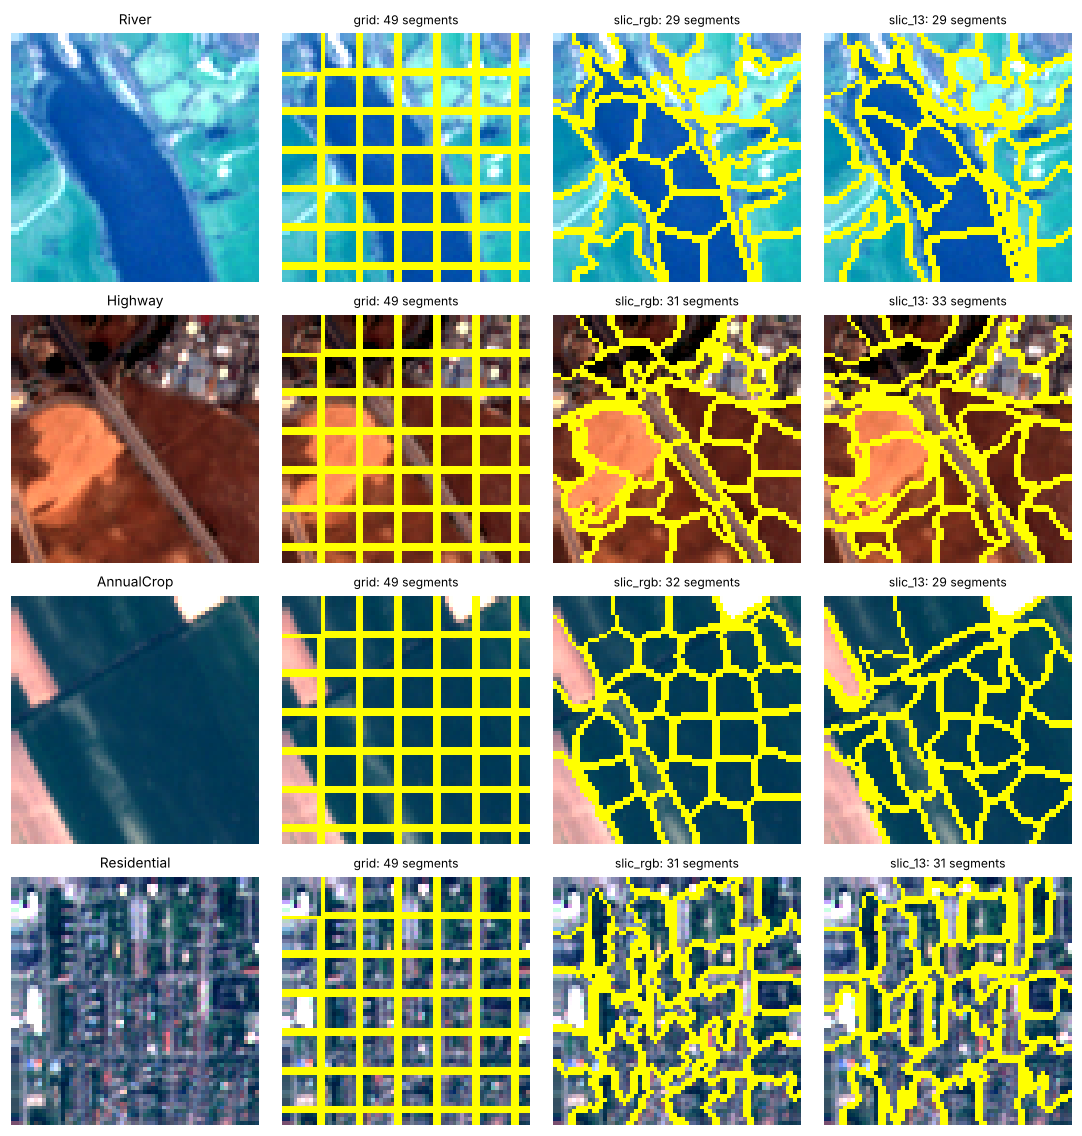

In [8]:
# slic cuts an image into superpixels; mark_boundaries draws their borders on a
# picture.
from skimage.segmentation import slic, mark_boundaries

# Ridge = linear regression with a small penalty. It will be LIME's simple
# "surrogate" model.
from sklearn.linear_model import Ridge


# ---------- bands_unit: bring all bands to the same scale before segmenting
def bands_unit(x, channels=range(13)):
    # Take the chosen bands as a NumPy array of shape (C, H, W).
    a = x[list(channels)].float().numpy()
    # For every band, find its dark end (2nd percentile) and its bright end
    # (98th percentile) in this image.
    lo, hi = np.percentile(a, 2, axis=(1, 2), keepdims=True), np.percentile(
        a, 98, axis=(1, 2), keepdims=True
    )
    # Rescale every band to the range 0..1 and move the channels last: (H, W,
    # C), the layout that slic expects.
    return np.clip((a - lo) / (hi - lo + 1e-6), 0, 1).transpose(1, 2, 0)


# ---------- segment: cut an image into about n_segments regions ("superpixels")
# It returns a (64, 64) array: the region number of every pixel. Three ways to
# cut:
def segment(x, method="slic_13", n_segments=N_SEGMENTS):
    # Height and width of the image.
    H, W = x.shape[-2:]
    if method == "grid":
        # A plain grid of squares. `cell` = side of a square, `ncol` = number of
        # squares per row (rounded up).
        cell = max(4, int(round(H / np.sqrt(n_segments))))
        ncol = -(-W // cell)
        # rr, cc = the row and the column of every pixel. Square number = (row
        # of the square) * ncol + (column of the square).
        rr, cc = np.mgrid[0:H, 0:W]
        seg = (rr // cell) * ncol + cc // cell
    elif method == "slic_rgb":
        # SLIC groups neighbouring pixels of similar colour. Here it only looks
        # at the colour picture (3 bands).
        seg = slic(
            rgb(x),
            n_segments=n_segments,
            compactness=10,
            sigma=1,
            start_label=0,
        )
    elif method == "slic_13":
        # The same, but SLIC looks at all 13 bands, so regions follow what the
        # satellite sees, not only what our eyes see.
        seg = slic(
            bands_unit(x),
            n_segments=n_segments,
            compactness=0.2,
            sigma=1,
            start_label=0,
            channel_axis=-1,
            convert2lab=False,
        )
    else:
        raise ValueError(method)
    # Renumber the regions 0, 1, 2, ... without gaps.
    seg = np.unique(seg, return_inverse=True)[1].reshape(H, W)
    # Safety net: on a nearly uniform image SLIC can return only a few regions.
    # Then use the grid instead.
    if method != "grid" and seg.max() + 1 < n_segments // 4:
        print(
            f"  {method} gave only {seg.max() + 1} segments; using the grid instead"
        )
        return segment(x, "grid", n_segments)
    return seg


# ---------- look at the three segmentations on four example images ----------
SEG_METHODS = ["grid", "slic_rgb", "slic_13"]
# The classes to show (only those for which we have an example image).
show = [
    c
    for c in ["River", "Highway", "AnnualCrop", "Residential"]
    if c in EXAMPLES
]
# A grid of pictures: one row per image, 4 columns (the picture + 3
# segmentations).
fig, axes = plt.subplots(len(show), 4, figsize=(10, 2.6 * len(show)))
for r, cls in enumerate(show):
    # The example image of this class.
    x = X[EXAMPLES[cls]]
    # Column 0: the plain picture.
    axes[r, 0].imshow(rgb(x))
    axes[r, 0].set_title(cls, fontsize=9)
    # Columns 1 to 3: the picture with the region borders in yellow, and the
    # number of regions in the title.
    for k, m in enumerate(SEG_METHODS):
        seg = segment(x, m)
        axes[r, k + 1].imshow(
            mark_boundaries(rgb(x), seg, color=(1, 1, 0), mode="inner")
        )
        axes[r, k + 1].set_title(f"{m}: {seg.max() + 1} segments", fontsize=8)
# Hide the axes of all panels and show the figure.
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

> **What to notice.** The `grid` squares ignore the image. The two `slic` versions follow the river, the road and the field edges. `slic_13` uses all 13 bands, so it can separate surfaces that look the same in true colour.

## 2. LIME by hand · 🟢 core

The whole method in about 15 lines (the `lime` package does the same; section 8 checks this):

1. Sample $N$ random on/off vectors $z' \in \{0,1\}^d$ (the first one keeps everything).
2. Build the perturbed images (removed superpixels → training mean in all 14 channels) and ask the model for $p(\text{class})$.
3. Weight each sample by its proximity to $x$: an exponential kernel on the cosine distance between $z'$ and the all-ones vector.
4. Fit a weighted ridge regression $g(z') = w_0 + \sum_j w_j z'_j$.
5. Read the weights $w_j$ (the explanation) and the weighted $R^2$ (the fidelity).

In [9]:
# ---------- lime_kernel: how much does each sample count? ----------
# LIME wants a LOCAL explanation, so samples that are close to the original
# image (few regions removed) get a large weight,
# and samples that are far from it (most regions removed) get a small weight.
#   Z : the on/off table, shape (samples, players). The original image is the
#       row of all 1s.
def lime_kernel(Z, kernel_width=KERNEL_WIDTH):
    # d = number of players (columns). on = how many players are switched on in
    # each row.
    d = Z.shape[1]
    on = Z.sum(1)
    # Distance of each row from the all-ones row (cosine distance). For 0/1 rows
    # this is 1 - on / (sqrt(on) * sqrt(d)):
    # 0 when everything is on (the original image), close to 1 when almost
    # everything is off. 1e-12 avoids dividing by 0.
    dist = 1 - on / (np.sqrt(on) * np.sqrt(d) + 1e-12)
    # Turn the distance into a weight with a bell-shaped curve: distance 0 ->
    # weight 1, large distance -> weight near 0.
    # kernel_width decides how fast the weight falls. (The square root is how
    # the lime package defines it.)
    return np.sqrt(np.exp(-(dist**2) / kernel_width**2))


# ---------- lime_explain: the whole LIME method, five steps ----------
#   x        : the image to explain
#   target   : the class we explain (a number 0..9)
#   segments : the superpixel map from segment(); None = use the 14 channels as
#              players instead
def lime_explain(
    x,
    target,
    segments=None,
    n_samples=N_SAMPLES,
    kernel_width=KERNEL_WIDTH,
    seed=0,
    alpha=1.0,
):
    # d = number of players: 14 channels, or the number of superpixels (largest
    # region number + 1).
    d = N_CH if segments is None else int(segments.max()) + 1
    # A random number generator with a fixed seed: the same seed gives the same
    # samples.
    rng = np.random.default_rng(seed)
    # Step 1, SAMPLE: a table of n_samples rows of random 0s and 1s. Each row
    # switches a random half of the players off.
    # The first row is set to all 1s, so the original image is always one of the
    # samples.
    Z = rng.integers(0, 2, size=(n_samples, d))
    Z[0] = 1
    # Step 2, ASK THE MODEL: for every row, remove the switched-off players and
    # read the model's probability of `target`.
    yv = coalition_proba(x, Z, target, segments)
    # Step 3, WEIGH: samples close to the original image count more.
    w = lime_kernel(Z, kernel_width)
    # Step 4, FIT A SIMPLE MODEL: a weighted linear regression that predicts the
    # probability yv from the on/off table Z.
    #   probability  ≈  intercept + coef[0] * z[0] + coef[1] * z[1] + ...
    g = Ridge(alpha=alpha).fit(Z, yv, sample_weight=w)
    # Step 5, READ THE EXPLANATION: coef[j] is the weight of player j. Positive
    # = keeping region j raises the probability.
    # r2 (between 0 and 1) says how well the simple model imitates the real
    # model on these samples: the "fidelity".
    return dict(
        coef=g.coef_,
        intercept=g.intercept_,
        r2=g.score(Z, yv, sample_weight=w),
        segments=segments,
    )


# ---------- lime_map: paint the weights back onto the image ----------
def lime_map(e):
    # e["segments"] holds the region number of every pixel; indexing coef with
    # it gives every pixel the weight of its region.
    return e["coef"][e["segments"]]

### ✅ Check: `lime_kernel` and `lime_explain`

In [10]:
# ---- Test 1: the kernel on three tiny cases with a known answer ----
# Three rows with 4 players: everything on, half on, everything off.
Zt = np.array([[1, 1, 1, 1], [1, 1, 0, 0], [0, 0, 0, 0]])
wt = lime_kernel(Zt, 0.25)
# Everything on must give weight 1; the other two are compared with the formula
# computed by hand.
assert np.allclose(
    wt,
    [
        1.0,
        np.sqrt(np.exp(-((1 - 2 / (np.sqrt(2) * 2)) ** 2) / 0.25**2)),
        np.sqrt(np.exp(-1 / 0.25**2)),
    ],
    atol=1e-6,
), f"got {wt}"
# ---- Test 2: a quick LIME run on the River example ----
# i = the number of the River example image, c = the number of the class River,
# seg = its superpixels.
i, c = EXAMPLES["River"], CLASSES.index("River")
seg = segment(X[i])
e = lime_explain(X[i], c, seg, n_samples=200)
# There must be one weight per superpixel, and the fidelity R² must lie between
# 0 and 1.
assert (
    e["coef"].shape == (seg.max() + 1,) and 0 <= e["r2"] <= 1
), "one weight per superpixel, and R² between 0 and 1"
print(f"✅ LIME works (R² = {e['r2']:.2f})")

✅ LIME works (R² = 0.48)


> **What this cell does.** It runs your LIME on one image per class. Top row: the image with its superpixels in yellow. Bottom row: each superpixel coloured by its LIME weight.

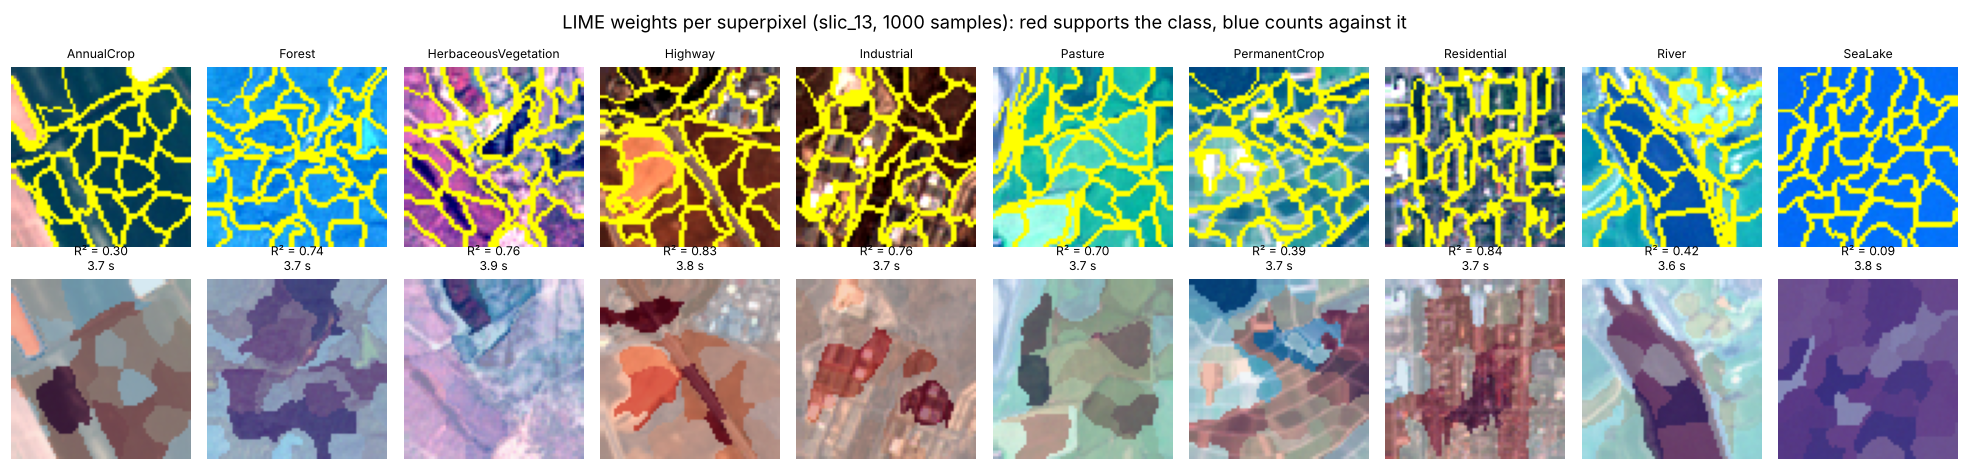

In [11]:
# Explain the example image of every class, and keep the explanations in the
# dictionary LIME.
LIME = {}
# Two rows of 10 pictures: top = the image with its superpixels, bottom = the
# LIME map.
fig, axes = plt.subplots(2, 10, figsize=(18, 4.4))
for j, (cls, i) in enumerate(EXAMPLES.items()):
    # Cut the image into superpixels, and start a stopwatch.
    seg = segment(X[i])
    t = time.time()
    # Run LIME for the image's own class.
    LIME[cls] = e = lime_explain(X[i], CLASSES.index(cls), seg)
    # Top row: the picture with the superpixel borders in yellow.
    axes[0, j].imshow(
        mark_boundaries(rgb(X[i]), seg, color=(1, 1, 0), mode="inner")
    )
    axes[0, j].axis("off")
    axes[0, j].set_title(cls, fontsize=8)
    # Bottom row: the LIME weights painted on the picture. The title shows the
    # fidelity R² and the time it took.
    show_map(
        axes[1, j],
        X[i],
        lime_map(e),
        f"R² = {e['r2']:.2f}\n{time.time() - t:.1f} s",
    )
plt.suptitle(
    f"LIME weights per superpixel (slic_13, {N_SAMPLES} samples): red supports the class, blue counts against it"
)
plt.tight_layout()
plt.show()

> **What to notice.** Red superpixels raise the probability of the class when they are kept; blue ones lower it. For River and Highway the red regions should lie on the water and the road. `R²` says how well the simple linear model imitates the CNN near this image: close to 1 is good, a low value means the explanation is a poor copy of the model.

## 3. The top two classes of an ambiguous image · ⚪ if time

As in the LIME paper's guitar/Labrador figure: one explanation per class. The superpixels with the largest positive weight for each class,
the rest greyed out.

> **What this cell does.** It takes the image the model is unsure about and explains its two most likely classes separately.

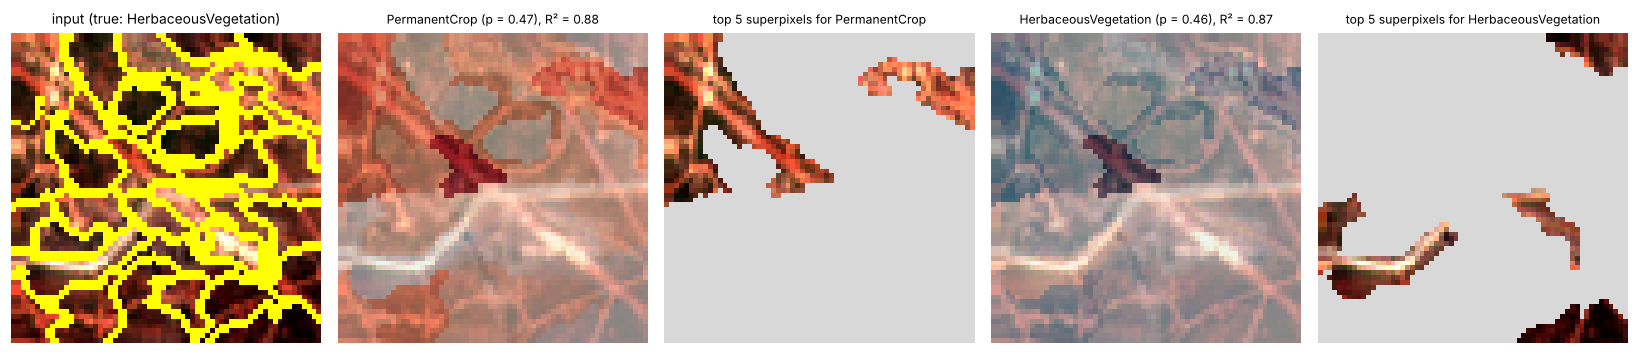

In [12]:
# Take the image the model hesitates on. `top` = its two most probable classes.
# `seg` = its superpixels.
i = AMBIGUOUS
top = np.argsort(P[i])[::-1][:2]
seg = segment(X[i])
# Five pictures in a row: the image, then (map, top-5 regions) for each of the
# two classes.
fig, axes = plt.subplots(1, 5, figsize=(15, 3.3))
# Picture 0: the image with its superpixels and its true class.
axes[0].imshow(mark_boundaries(rgb(X[i]), seg, color=(1, 1, 0), mode="inner"))
axes[0].set_title(f"input (true: {CLASSES[y_test[i]]})", fontsize=9)
axes[0].axis("off")
for k, c in enumerate(top):
    # One LIME explanation per class: same image, same superpixels, a different
    # question ("why class c?").
    e = lime_explain(X[i], c, seg)
    # The LIME map for class c.
    show_map(
        axes[1 + 2 * k],
        X[i],
        lime_map(e),
        f"{CLASSES[c]} (p = {P[i, c]:.2f}), R² = {e['r2']:.2f}",
    )
    # The 5 superpixels with the largest weights; `keep` is True for the pixels
    # inside them.
    keep = np.isin(seg, np.argsort(e["coef"])[::-1][:5])
    # Show only those 5 regions; everything else is painted light grey.
    axes[2 + 2 * k].imshow(
        np.where(keep[..., None], rgb(X[i]), 0.85 * np.ones(3))
    )
    axes[2 + 2 * k].axis("off")
    axes[2 + 2 * k].set_title(f"top 5 superpixels for {CLASSES[c]}", fontsize=8)
plt.tight_layout()
plt.show()

> **What to notice.** The two classes should point at different superpixels. An explanation always answers the question *why this class?*

## 4. Does the segmentation change the explanation? · 🟢 core

Same image, same model, same LIME settings, three segmentations. Fidelity ($R^2$) tells us which surrogate fits the model better locally,
but not which one a user should believe.

> **What this cell does.** Same image, same model, same LIME settings; only the way of cutting the image into superpixels changes.

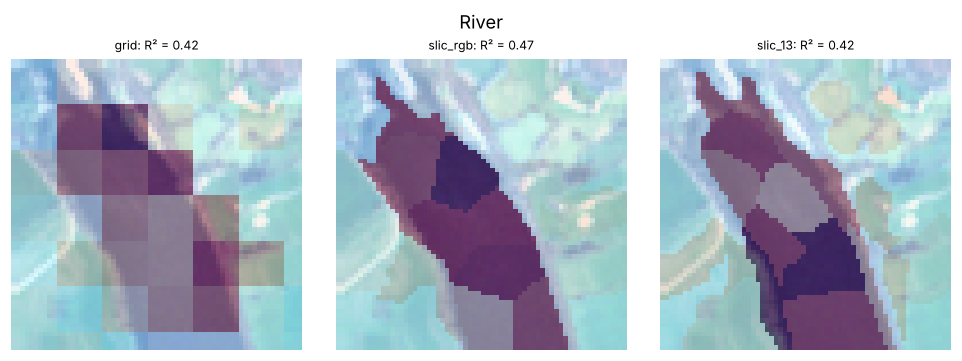

In [13]:
# The River example: i = the image number, c = the class number.
RIVER = "River"
i, c = EXAMPLES[RIVER], CLASSES.index(RIVER)
fig, axes = plt.subplots(1, 3, figsize=(9, 3.3))
# Same image, same model, same LIME settings. Only the way of cutting the image
# changes.
for ax, m in zip(axes, SEG_METHODS):
    e = lime_explain(X[i], c, segment(X[i], m))
    show_map(ax, X[i], lime_map(e), f"{m}: R² = {e['r2']:.2f}")
plt.suptitle(RIVER)
plt.tight_layout()
plt.show()

> **What to notice.** The three maps differ. The choice of superpixels is made by the person who runs LIME, and it changes the explanation.

## 5. Stability: run LIME again with another seed · 🟢 core

LIME is random. With few samples, two runs on the **same** image can rank the superpixels differently. We repeat LIME with 5 seeds for
several sample sizes and measure (a) the mean pairwise Spearman correlation of the weights and (b) the overlap of the top-5 superpixels.

> **What this cell does.** LIME uses random samples, so two runs can disagree. This cell runs LIME 5 times with different random seeds, for several numbers of samples, and measures how much the 5 runs agree.

,samples,Spearman between runs,top-5 overlap,mean R²
0,50,0.249,0.26,0.688
1,100,0.543,0.58,0.505
2,300,0.792,0.78,0.443
3,1000,0.872,0.92,0.430


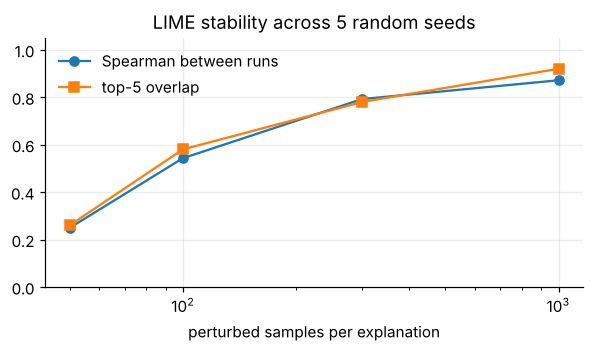

In [14]:
# The superpixels of the River image; `rows` will collect one line of results
# per sample size.
seg = segment(X[i])
rows = []
# Try several numbers of samples (fewer on a CPU to save time).
for n in ([50, 100, 300, 1000, 3000] if GPU else [50, 100, 300, 1000]):
    # Run LIME 5 times on the SAME image. Only the random seed changes.
    runs = [lime_explain(X[i], c, seg, n_samples=n, seed=s) for s in range(5)]
    # W = the 5 weight vectors as one table (5 rows). top5 = for each run, the
    # set of its 5 most important superpixels.
    W = np.array([r["coef"] for r in runs])
    top5 = [set(np.argsort(w)[::-1][:5]) for w in W]
    # All pairs of runs: (0,1), (0,2), ..., (3,4). That is 10 pairs.
    pairs = [(a, b) for a in range(5) for b in range(a + 1, 5)]
    # Two ways to measure whether two runs agree, averaged over the 10 pairs:
    #   Spearman      : do the two runs rank the superpixels in the same order?
    #                   (1 = same order, 0 = unrelated)
    #   top-5 overlap : how many of the 5 most important superpixels do the two
    #   runs share, divided by 5?
    # mean R² is the average fidelity of the 5 runs.
    rows.append(
        {
            "samples": n,
            "Spearman between runs": np.mean(
                [spearmanr(W[a], W[b])[0] for a, b in pairs]
            ),
            "top-5 overlap": np.mean(
                [len(top5[a] & top5[b]) / 5 for a, b in pairs]
            ),
            "mean R²": np.mean([r["r2"] for r in runs]),
        }
    )
# Show the results as a table.
stab = pd.DataFrame(rows)
display(stab.round(3))
# And as a plot: agreement between runs (vertical) against the number of samples
# (horizontal, log scale).
fig, ax = plt.subplots(figsize=(5.5, 3.3))
ax.plot(
    stab["samples"],
    stab["Spearman between runs"],
    "o-",
    label="Spearman between runs",
)
ax.plot(stab["samples"], stab["top-5 overlap"], "s-", label="top-5 overlap")
ax.set_xscale("log")
ax.set_xlabel("perturbed samples per explanation")
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)
ax.set_title("LIME stability across 5 random seeds")
plt.tight_layout()
plt.show()

> **What to notice.** With 50 samples the runs agree poorly (low values); with 1,000 they agree much better. An explanation that changes when you run it again should not be shown to a user.

## 6. The kernel width: how local is "local"? · ⚪ if time

A small width trusts only samples that remove very little; a very large width weights all samples equally, so the surrogate becomes a
global linear fit over the random masks.

> **What this cell does.** It repeats LIME with different kernel widths: a small width only trusts samples very close to the image, a large width treats all samples the same.

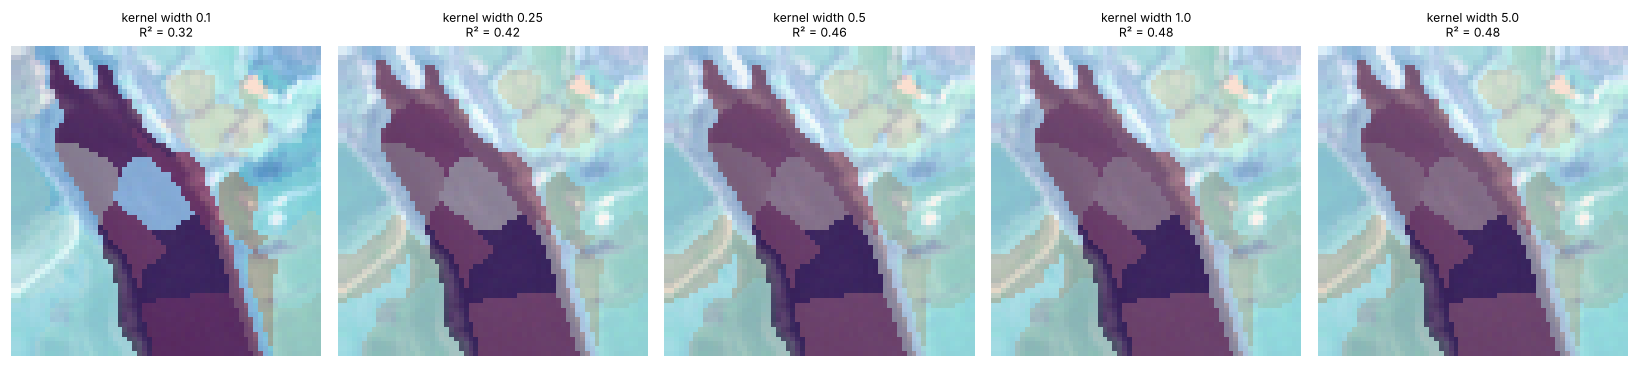

In [15]:
# Five kernel widths, from very local (0.1) to "all samples count the same"
# (5.0).
widths = [0.1, 0.25, 0.5, 1.0, 5.0]
fig, axes = plt.subplots(1, len(widths), figsize=(3 * len(widths), 3.3))
for ax, kw in zip(axes, widths):
    # The same River image and superpixels as before; only the kernel width
    # changes.
    e = lime_explain(X[i], c, seg, kernel_width=kw)
    show_map(ax, X[i], lime_map(e), f"kernel width {kw}\nR² = {e['r2']:.2f}")
plt.tight_layout()
plt.show()

> **What to notice.** The map and its R² change with the width. There is no single correct value; it is one more choice of the user.

## 7. Spectral LIME: the 14 channels as features · ⚪ if time

Nothing in LIME requires spatial features. Here $z'_j = 1$ keeps channel $j$ and $z'_j = 0$ sets the whole channel to its training mean.
The weights are a **local** band importance for one image: compare them with the global PCI ranking and with the one-band occlusion of lab 1.
The NOISE weight should be close to 0.

> **What this cell does.** LIME again, but now the on/off features are the 14 channels instead of superpixels: which **bands** matter for this one image?

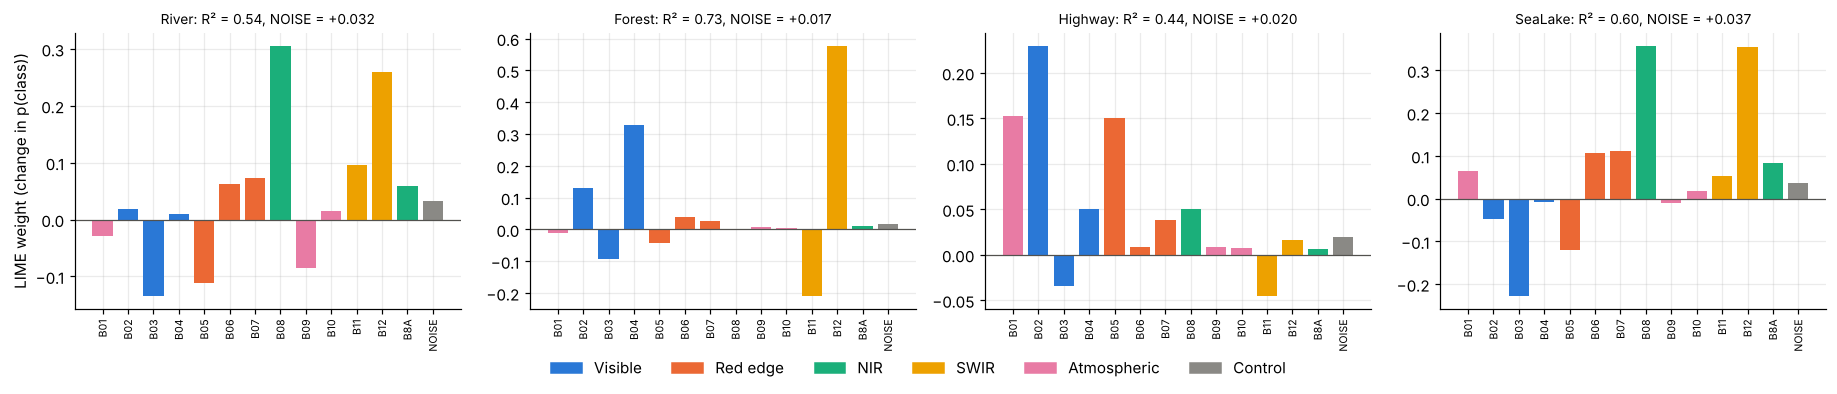

In [16]:
# The classes to show (only those for which we have an example image).
show = [c for c in ["River", "Forest", "Highway", "SeaLake"] if c in EXAMPLES]
# One bar chart per image.
fig, axes = plt.subplots(
    1, len(show), figsize=(4.2 * len(show), 3.4), sharey=False
)
for ax, cls in zip(axes, show):
    i, c = EXAMPLES[cls], CLASSES.index(cls)
    # segments=None: the players are now the 14 CHANNELS. A sample keeps some
    # whole bands and removes the others.
    e = lime_explain(X[i], c, segments=None)
    # One bar per channel = its LIME weight, coloured by spectral group.
    ax.bar(
        CHANNEL_NAMES,
        e["coef"],
        color=[GROUP_COLORS[GROUP_OF[ch]] for ch in CHANNEL_NAMES],
    )
    # A line at 0, and the band names written vertically.
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    # The title shows the fidelity and the weight of the NOISE channel (the last
    # one), which should be close to 0.
    ax.set_title(
        f"{cls}: R² = {e['r2']:.2f}, NOISE = {e['coef'][-1]:+.3f}", fontsize=9
    )
axes[0].set_ylabel("LIME weight (change in p(class))")
# A colour legend for the spectral groups, below the charts.
handles = [
    plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in GROUP_COLORS
]
fig.legend(
    handles,
    list(GROUP_COLORS),
    frameon=False,
    ncol=6,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.06),
)
plt.tight_layout()
plt.show()

> **What to notice.** The bars differ from class to class. The NOISE bar (last) should be close to 0: the model ignores the noise channel.

## 8. Cross-check with the `lime` package (optional) · ⚪ if time

`lime_image` works on any number of channels when `hide_color` is a number. We give it our segmentation and `hide_color=0` (the training mean)
and compare its weights with ours. They should broadly agree, but not exactly: different random samples.

> **What this cell does.** It runs the official `lime` package on the same image and compares its weights with yours.

Spearman(lime package, by hand) = 0.89   R² package = 0.44


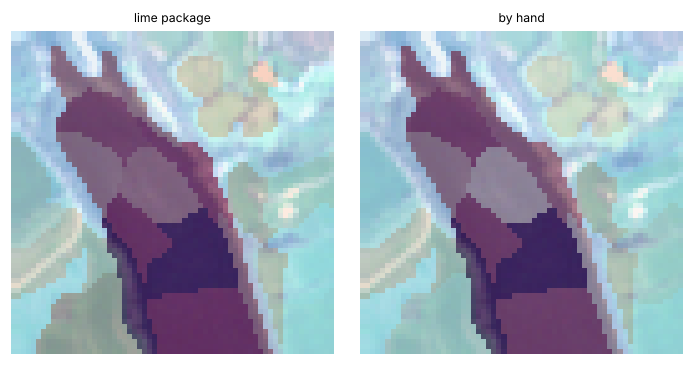

In [17]:
try:
    # The official LIME package for images.
    from lime import lime_image

    # The River image again, with its superpixels.
    i, c = EXAMPLES[RIVER], CLASSES.index(RIVER)
    seg = segment(X[i])
    # The package wants the image as (H, W, channels), so move the 14 channels
    # last.
    img = X[i].float().numpy().transpose(1, 2, 0).astype(np.float64)
    # The package also wants a function "batch of images in, probabilities out".
    # We move the channels back and call our model.
    classifier = lambda batch: predict_proba(
        torch.from_numpy(np.asarray(batch, dtype=np.float32)).permute(
            0, 3, 1, 2
        )
    )
    # Run the package with OUR settings: the same kernel width, the same number
    # of samples, removed regions set to 0,
    # and our own superpixels (segmentation_fn returns seg).
    exp = lime_image.LimeImageExplainer(
        kernel_width=KERNEL_WIDTH, random_state=0
    ).explain_instance(
        img,
        classifier,
        labels=(c,),
        top_labels=None,
        hide_color=0,
        num_samples=N_SAMPLES,
        batch_size=256,
        segmentation_fn=lambda _: seg,
        random_seed=0,
    )
    # Copy the package's weights into an array: lib[j] = weight of superpixel j.
    lib = np.zeros(seg.max() + 1)
    for j, v in exp.local_exp[c]:
        lib[j] = v
    # Our own weights for the same image.
    ours = lime_explain(X[i], c, seg)["coef"]
    # Do the two rank the superpixels in the same order? (Spearman close to 1 =
    # yes.)
    print(
        f"Spearman(lime package, by hand) = {spearmanr(lib, ours)[0]:.2f}   R² package = {exp.score:.2f}"
    )
    # Show both maps side by side.
    fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.3))
    show_map(axes[0], X[i], lib[seg], "lime package")
    show_map(axes[1], X[i], ours[seg], "by hand")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("lime is not installed: run  !pip install lime  and re-run this cell")

> **What to notice.** A Spearman correlation near 1 means your by-hand LIME and the package agree on the ranking of the superpixels.

## 9. Questions for discussion

1. Which segmentation would you use for satellite images, and why? Is a segmentation that follows the RGB image "neutral"?
2. In section 3, do the two classes rely on different superpixels? Compare with the two occlusion maps of lab 1.
3. A run with $R^2 = 0.2$: what does LIME's explanation mean then? Should a tool show the explanation at all?
4. From section 5, how many samples would you need before you would show this explanation to a user?
5. Section 7 gives a band importance for one image. How is it different from PCI (global, accuracy, shuffle) and from the one-band occlusion of
   lab 1 (single removal, no surrogate)?
6. LIME removes superpixels by setting them to the training mean, exactly like occlusion's mean fill. Which conclusions would change with
   another fill?

**Try it.**
* Re-run section 2 with `segment(x, "grid")`. Which classes change the most?
* Set `N_SEGMENTS = 15` and `100`. What happens to $R^2$ and to the maps?
* Spectral LIME on a misclassified image: which bands pushed the model towards the wrong class?

**References:** M. T. Ribeiro, S. Singh, C. Guestrin, *"Why Should I Trust You?": Explaining the Predictions of Any Classifier*, KDD 2016.
R. Achanta et al., *SLIC Superpixels Compared to State-of-the-Art Superpixel Methods*, IEEE TPAMI 2012.